<a href="https://colab.research.google.com/github/YosepAI/start2/blob/master/lab1_etudiant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 1 — Méthodes numériques pour les ingénieurs
**Recherche de racines : dichotomie, Newton-Raphson et fausse position**

## Consignes
L'objectif est d'implémenter trois méthodes numériques pour résoudre $f(x)=0$, de visualiser leur convergence et de comparer leur comportement.

Complétez uniquement les cellules indiquées.  
Les outils de visualisation et les appels de test sont déjà fournis.

## Outils fournis

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

def plot_function(f, xmin=-3, xmax=6, root=None, history=None, title="Fonction"):
    xs = np.linspace(xmin, xmax, 500)
    fig, ax = plt.subplots()
    ax.plot(xs, f(xs), label="f(x)")
    ax.axhline(0, color="black", linewidth=1)

    if history is not None and len(history) > 0:
        h = np.asarray(history, dtype=float)
        ax.scatter(h, f(h), c=np.arange(len(h)), cmap="viridis", label="Itérés")

    if root is not None:
        ax.scatter([root], [f(root)], marker="*", s=150,
                   label=f"Résultat : {root:.7f}")

    ax.set(xlabel="x", ylabel="f(x)", title=title)
    ax.legend()
    plt.show()

def show_history(history, f, limit=12):
    print(f"{'Indice':>6} {'Approximation':>16} {'f(x)':>16}")
    for k, x in enumerate(history[:limit]):
        print(f"{k:6d} {x:16.9f} {f(x):16.3e}")
    if len(history) > limit:
        print(f"... {len(history)-limit} approximations supplémentaires enregistrées")

def plot_newton_tangents(f, df, history, xmin=-3, xmax=6, limit=None):
    xs = np.linspace(xmin, xmax, 500)
    fig, ax = plt.subplots()
    ax.plot(xs, f(xs), label="f(x)")
    ax.axhline(0, color="black", linewidth=1)

    points = history if limit is None else history[:limit]
    for k, xk in enumerate(points):
        tangent = f(xk) + df(xk) * (xs - xk)
        ax.plot(xs, tangent, "--", label=f"Tangente en x{k}={xk:.3f}")
        ax.scatter([xk], [f(xk)])

    ax.set(xlabel="x", ylabel="y",
           title="Newton : tangentes et intersections avec l'axe des abscisses")
    ax.legend()
    plt.show()

def compare_convergence(histories, reference):
    fig, ax = plt.subplots()
    for name, history in histories.items():
        errors = np.maximum(np.abs(np.asarray(history, dtype=float) - reference), 1e-16)
        ax.semilogy(range(1, len(history) + 1), errors, "o-", label=name)

    ax.set(xlabel="Numéro de la mise à jour",
           ylabel="Erreur absolue",
           title="Distance à la racine de référence")
    ax.legend()
    plt.show()

# 1. Dichotomie

### Principe
On part d'un intervalle $[a,b]$ tel que $f(a)$ et $f(b)$ soient de signes opposés.  
À chaque itération :

$$
c=\frac{a+b}{2}
$$

puis on conserve la moitié qui contient encore un changement de signe.  
On s'arrête lorsque la largeur de l'intervalle devient inférieure à la tolérance.

### Code Python
**Fonction :** $f_B(x)=x^3-4x^2+6$  
**Tolérance :** `1e-5`.

In [ ]:
def f_b(x):
    return x**3 - 4*x**2 + 6

def df_b(x):
    return 3*x**2 - 8*x


def bisection(f, a, b, tol=1e-5):
    history = []

    while abs(b-a)>tol :
      m=(a+b)/2
      history.append(m)
      if f(a)*f(m)<0 :
        b=m
      else :
        a=m
    return m, history



Indice    Approximation             f(x)
     0     -1.000000000        1.000e+00
     1     -1.500000000       -6.375e+00
     2     -1.250000000       -2.203e+00
     3     -1.125000000       -4.863e-01
     4     -1.062500000        2.849e-01
     5     -1.093750000       -9.360e-02
     6     -1.078125000        9.742e-02
     7     -1.085937500        2.356e-03
     8     -1.089843750       -4.551e-02
     9     -1.087890625       -2.155e-02
    10     -1.086914062       -9.590e-03
    11     -1.086425781       -3.615e-03
... 6 approximations supplémentaires enregistrées
Racine négative approchée : -1.0861282348632812


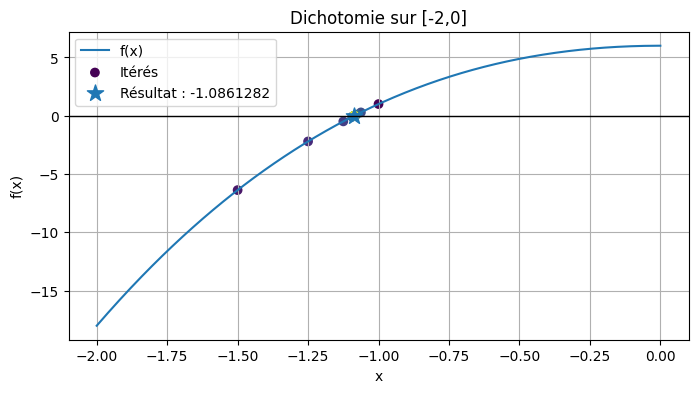

In [ ]:
root_b, hist_b = bisection(f_b, -2, 0, tol=1e-5)

show_history(hist_b, f_b)
print("Racine négative approchée :", root_b)

plot_function(
    f_b,
    xmin=-2,
    xmax=0,
    root=root_b,
    history=hist_b,
    title="Dichotomie sur [-2,0]"
)

### Expériences
Testez `tol=1e-2`, `1e-5`, puis `1e-8`.  
Essayez aussi les intervalles `[1,2]`, `[3,4]` et `[4,5]`.

In [ ]:
x1,H1 = bisection(f_b,1,2,0.01)
x2,H2 = bisection(f_b,3,4,0.01)
x3,H3 = bisection(f_b,4,5,0.01)
print(x1,x2,x3)
print(H1,H2,H3)

1.5703125 3.5078125 4.9921875
[1.5, 1.75, 1.625, 1.5625, 1.59375, 1.578125, 1.5703125] [3.5, 3.75, 3.625, 3.5625, 3.53125, 3.515625, 3.5078125] [4.5, 4.75, 4.875, 4.9375, 4.96875, 4.984375, 4.9921875]


### Conclusion
**À compléter :** que remarquez-vous sur la largeur de l'intervalle et le nombre d'itérations ?

# 2. Newton-Raphson

### Principe
Pour résoudre $f(x)=0$, Newton utilise la tangente au point courant :

$$
x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}.
$$

La méthode est généralement rapide près d'une racine, mais elle nécessite une dérivée utilisable et dépend du point initial.

### Code Python
**Fonction :** $f_N(x)=x^2-2x-3$.

In [ ]:
def f_n(x):
    return x**2 - 2*x - 3

def df_n(x):
    return 2*x - 2

def newton(f, df, x0, tol=1e-5):
    xk = x0
    history = [xk]

    while abs(f(xk))>tol :
      xk = xk - f(xk)/df(xk)
      history.append(xk)
    return xk, history



Indice    Approximation             f(x)
     0      5.000000000        1.200e+01
     1      3.500000000        2.250e+00
     2      3.050000000        2.025e-01
     3      3.000609756        2.439e-03
     4      3.000000093        3.717e-07


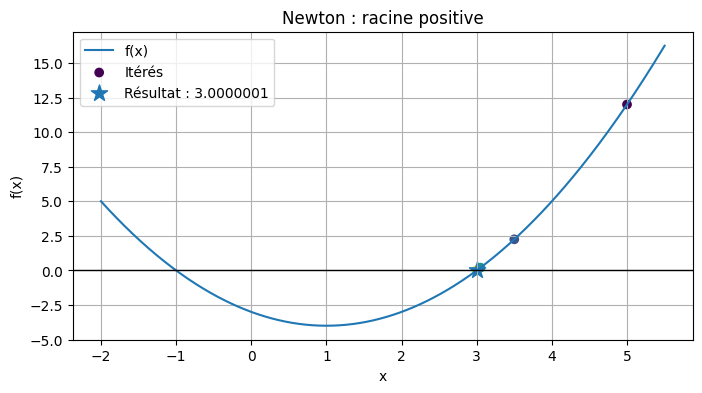

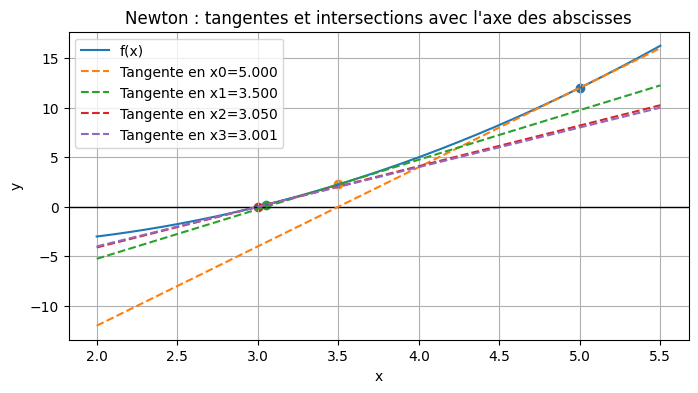

In [ ]:
root_n, hist_n = newton(f_n, df_n, 5)

show_history(hist_n, f_n)

plot_function(
    f_n,
    xmin=-2,
    xmax=5.5,
    root=root_n,
    history=hist_n,
    title="Newton : racine positive"
)

plot_newton_tangents(
    f_n,
    df_n,
    hist_n[:-1],
    xmin=2,
    xmax=5.5
)

### Expériences
Testez `x0=0`, `x0=5` et `x0=1`.  
Newton trouve-t-il toujours la même racine ?

In [ ]:
x1,H1 = newton(f_n, df_n, 0, tol=1e-5)
x2,H2 = newton(f_n, df_n, 5, tol=1e-5)
x3,H3 = newton(f_n, df_n, 10, tol=1e-5)
print(x1,x2,x3)
print(H1,H2,H3)

-1.0000000929222947 3.0000000929222947 3.0000020923367052
[0, -1.5, -1.05, -1.000609756097561, -1.0000000929222947] [5, 3.5, 3.05, 3.0006097560975613, 3.0000000929222947] [10, 5.722222222222222, 3.784640522875817, 3.1105458218181457, 3.002895075433833, 3.0000020923367052]


### Conclusion
**À compléter :** quel est l'effet du point initial ? Que se passe-t-il lorsque la dérivée est nulle ?

# 3. Fausse position

### Principe
On suit ici la formule utilisée dans le cours : la pente est estimée à partir de deux points successifs.

$$
x^{k+1}
=
x^k
-
f(x^k)
\frac{x^{k-1}-x^k}
{f(x^{k-1})-f(x^k)}.
$$

**Fonction étudiée :**

$$
f_{RF}(x)=\sin(x)-\frac{x}{2}.
$$

### Code Python

In [ ]:
def f_rf(x):
    return np.sin(x) - x/2

def df_rf(x):
    return np.cos(x) - 0.5

def regula_falsi(f, x0, x1, tol=1e-5):
    history = [x0,x1]
    while True :
      print("hi")
      x2 = x1 - f(x1)*(x1-x0)/(f(x1)-f(x0))
      history.append(x2)
      x0,x1 = x1,x2
      if abs(x1-x0)<tol or abs(f(x2))<tol :
        break

    return x1, history

Indice    Approximation             f(x)
     0      1.000000000        3.415e-01
     1      3.000000000       -1.359e+00
     2      1.401647647        2.849e-01
     3      1.678677837        1.548e-01
     4      2.008513236       -9.853e-02
     5      1.880247471        1.238e-02
     6      1.894561175        7.638e-04
     7      1.895502591       -6.818e-06


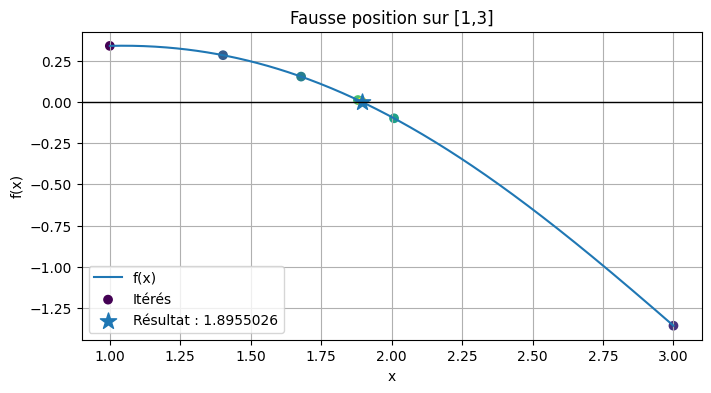

In [ ]:
root_rf, hist_rf = regula_falsi(f_rf, 1, 3, tol=1e-5)

show_history(hist_rf, f_rf)

plot_function(
    f_rf,
    xmin=1,
    xmax=3,
    root=root_rf,
    history=hist_rf,
    title="Fausse position sur [1,3]"
)

# 4. Comparaison des trois méthodes

Pour comparer les méthodes, on utilise la même fonction, la même tolérance et une racine de référence.  
On compare : la racine obtenue, le nombre de mises à jour, le résidu et l'erreur absolue.

In [ ]:

def compare_three(f, df, a, b, x0, reference, title):
    root_b, hist_b = bisection(f, a, b, tol=1e-5)
    root_n, hist_n = newton(f, df, x0, tol=1e-5)
    root_rf, hist_rf = regula_falsi(f, a, b, tol=1e-5)

    # On ne compte que les mises à jour effectives.
    hist_n_updates = hist_n[1:]
    hist_rf_updates = hist_rf[2:]

    print(title)
    print(f"{'Méthode':<18} {'Racine':>13} {'Itérations':>11} {'Résidu':>12} {'Erreur':>12}")

    rows = [
        ("Dichotomie", root_b, hist_b),
        ("Newton", root_n, hist_n_updates),
        ("Fausse position", root_rf, hist_rf_updates),
    ]

    for name, root, history in rows:
        print(
            f"{name:<18} {root:13.9f} {len(history):11d} "
            f"{abs(f(root)):12.3e} {abs(root-reference):12.3e}"
        )

    compare_convergence(
        {
            "Dichotomie": hist_b,
            "Newton": hist_n_updates,
            "Fausse position": hist_rf_updates,
        },
        reference,
    )

    return root_b, root_n, root_rf


In [ ]:
f_n(5)


12

hi
hi
hi
hi
hi
hi
comp
Méthode                   Racine  Itérations       Résidu       Erreur
Dichotomie           3.000001907          19    7.629e-06    1.907e-06
Newton               3.000000093           4    3.717e-07    9.292e-08
Fausse position      3.000000000           6    1.530e-09    3.824e-10


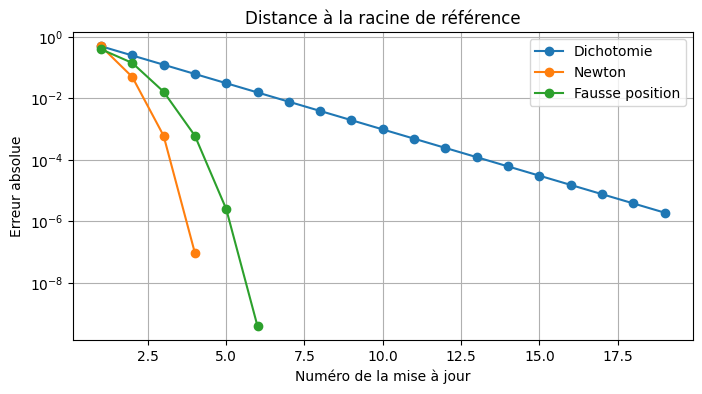

hi
hi
hi
hi
hi
hi
hi
hi
hi
comp
Méthode                   Racine  Itérations       Résidu       Erreur
Dichotomie          -1.086128235          18    2.400e-05    1.963e-06
Newton              -1.086130198           4    9.753e-10    7.976e-11
Fausse position     -1.086130197           9    2.426e-09    1.984e-10


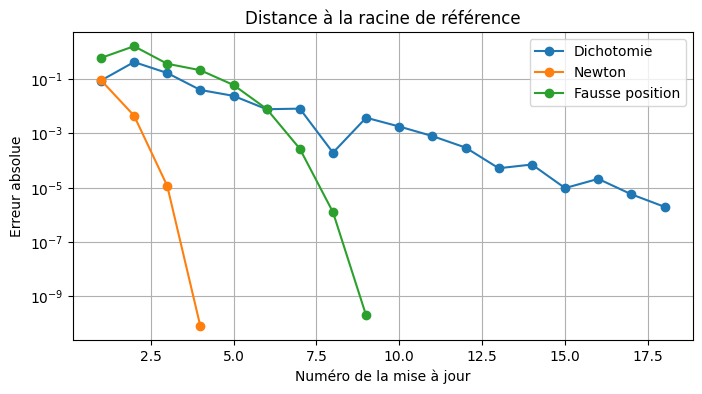

hi
hi
hi
hi
hi
hi
comp
Méthode                   Racine  Itérations       Résidu       Erreur
Dichotomie           1.895500183          18    4.845e-06    5.916e-06
Newton               1.895494267           3    1.431e-10    1.747e-10
Fausse position      1.895502591           6    6.818e-06    8.324e-06


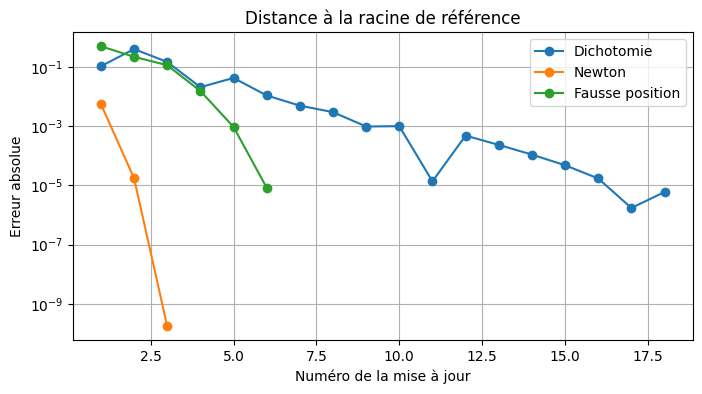

In [ ]:
reference_rf = 1.895494267033981
reference_b = -1.086130197651493
reference_n = 3.0

root1_b, root1_n, root1_rf = compare_three(f_n,df_n,2,5,5,3,"comp")
root2_b, root2_n, root2_rf = compare_three(f_b,df_b,-2,0,-1.55,-1.086130197651493,"comp")
root3_b, root3_n, root3_rf = compare_three(f_rf,df_rf,1,3,2,1.895494267033981,"comp")
# À vous : appelez compare_three sur :
# 1) f_rf sur [1,3] avec x0=2
# 2) f_b sur [-2,0] avec x0=-1.5
# 3) f_n sur [2,5] avec x0=5

### Discussion
- Pourquoi ne pas toujours utiliser Newton ?
- Un faible résidu $|f(x)|$ garantit-il toujours une faible erreur sur $x$ ?
- Quelle méthode est la plus robuste dans ce TP ?

### Vos conclusions
Résumez en quelques lignes les avantages et limites observés pour les trois méthodes.